# 01 · Preprocessing — Sun 2021 HCC (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, and remove detached islands. Sun et al.
profile hepatocellular carcinoma (18 patients, 10x); the malignant compartment is
small and patient-concentrated, so **Gate 1** (batch mixing + manifold continuity)
is the decisive test and is judged on the *embedding*, not a scalar.

Kürten 2021's malignant manifold *separated* into a cycling/metabolic lobe and an
embryonic lobe, and the trajectory had to be scoped to the embryonic one. Sun poses the
same question: a low-resolution Leiden **does** expose a cycling-enriched sub-region
(~32% cycling vs ~1% elsewhere), so we settle its biology before Gate 1 — the binding
*lobe-identity* lesson. The decisive difference from Kürten: Sun's cells stay **one
connected component** (the cycling lobe does not detach), the cycling lobe is **not**
gastrulation-high (it carries the *lowest* Gast), and removing it leaves the diagnostic
Gast↔Crest gradient essentially unchanged. So there is nothing to scope out: the
trajectory runs over the **full** manifold (the Bischoff 2021 lung precedent).
Every tunable choice is *derived from this dataset*, not inherited. Deliverable:
`processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Sun2021_Liver-Biliary | category: Liver-Biliary


### Load malignant compartment
Sun et al. annotate cell type directly; we take their `Malignant` calls. The matrix
is TPM (the loader passes it through and applies `log1p`).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Sun2021_Liver-Biliary
Done.
full atlas: (16498, 19744)
malignant: (2737, 19744) | samples: 18


### Sample thresholding — median-restricted multiplicative gap
We cut thin, spillover-dominated samples at the largest **multiplicative** cliff in the
sorted per-sample counts. A naive top-of-list gap-finder here lands on the *noise floor*
(the 8→3 tail, ratio 2.7) and would keep almost every sample — the failure mode seen on
Chen 2020. Restricting the search to samples **at or above the median count** isolates the
meaningful separatrix between real tumour-bearing samples and the sparse tail; the cut is
the geometric mean across that gap.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
med = np.median(vals)
ratios = vals[:-1] / vals[1:]
cand = [i for i in range(len(ratios)) if vals[i] >= med]   # restrict gap search to >= median
gap = max(cand, key=lambda i: ratios[i])
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'median count = {med:g}; median-restricted largest gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples {sorted(keep.tolist())} -> {adata.shape[0]} cells')

sorted per-sample counts: [593, 535, 376, 367, 269, 198, 80, 68, 52, 45, 35, 31, 27, 23, 19, 8, 8, 3]
median count = 48.5; median-restricted largest gap: 198 -> 80 (ratio 2.48)
derived threshold (geometric mean across the gap) = 125
kept 6/18 samples ['P04', 'P05', 'P09', 'P10', 'P16', 'P18'] -> 2338 cells


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs=20` is derived from the scree: PC variance falls to a flat ~0.1% tail after a
strong early elbow (a chord-elbow would cut at ~6 — the Chen under-powering trap — so we
stay above it, within the 10x precedent range). Harmony `theta=5` was selected from a
`theta` sweep (0/1/2/3/5/8) on the embedding: per-neighbourhood cross-sample mixing rises
from a per-patient archipelago (theta=0) to a plateau by theta≈5, and the kNN graph
resolves to a single connected component from theta≥2; theta=8 begins over-integrating.
theta=5 sits on the mixing plateau.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio (PC1..8):', np.round(vr[:8],4).tolist())
print('  tail (PC15,20,30,40):', np.round(vr[[14,19,29,39]],4).tolist(),
      '| cum var @20 =', round(float(np.cumsum(vr)[19]),3))
sce.pp.harmony_integrate(adata, 'sample', theta=5, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=0)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 7498 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 7498
PCA variance ratio (PC1..8): [0.171, 0.048, 0.0196, 0.013, 0.0103, 0.0101, 0.0045, 0.0032]
  tail (PC15,20,30,40): [0.0016, 0.0012, 0.001, 0.001] | cum var @20 = 0.301


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous manifold body.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=2).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('kept', adata.n_obs, 'cells in the main component')

removed 1 cells in 1 detached islands
kept 2337 cells in the main component


### Gate 1 — batch mixing, continuity, and the cycling-lobe (scope) decision
Three things decide Gate 1 and the trajectory scope. **(i) Mixing** — samples must intermix
(per-neighbourhood, iLISI-like), not form per-patient islands. **(ii) Continuity** — the cells
must form **one** connected kNN component. **(iii) The Kürten lobe-identity fork** — a
low-resolution Leiden exposes a cycling-enriched sub-region; before the GO we settle its
*biology* (embryonic signatures + cell cycle) and decide whether the trajectory must be scoped
to it (Kürten) or can run over the full manifold (Bischoff). The scope test is explicit: does
removing the cycling lobe change the diagnostic Gast↔Crest gradient, and is Gast
proliferation-confounded?

In [7]:
# (i) cross-sample mixing (per-neighbourhood, iLISI-like) + (ii) continuity
from sklearn.neighbors import NearestNeighbors as NN
k = 30
idx = NN(n_neighbors=k+1).fit(adata.obsm['X_pca_harmony'][:,:20]).kneighbors(return_distance=False)[:,1:]
s = adata.obs['sample'].values
diff_frac = (s[idx] != s[:,None]).mean()
p = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1 - (p**2).sum()
ncomp_knn, _ = connected_components(adata.obsp['connectivities'], directed=False)
print(f'diff-sample kNN fraction = {diff_frac:.3f} (perfect-mixing ceiling {ceiling:.3f})')
print(f'kNN-graph connected components = {ncomp_knn}  (1 = single continuous manifold)')

diff-sample kNN fraction = 0.428 (perfect-mixing ceiling 0.812)
kNN-graph connected components = 1  (1 = single continuous manifold)


In [8]:
# (iii) settle the cycling-enriched lobe's biology BEFORE the GO (Kurten lobe-identity lesson)
# score the three embryonic modules with the pipeline convention (union control pool, ctrl_as_ref=False)
feat = {}
for nm, fn in [('Gast','GSE162534'),('pSom','GSE229103'),('Crest','rRNAModifications'),('union','union')]:
    g = pd.read_csv(f'/home/caleb/MesenCoder/data/features/biomart/{fn}.csv')['hsapiens'].dropna().drop_duplicates()
    feat[nm] = [x for x in g if x in adata.var_names]
for nm in ['Gast','pSom','Crest']:
    sc.tl.score_genes(adata, feat[nm], score_name=nm, ctrl_as_ref=False, gene_pool=feat['union'], random_state=1234)

sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=0)   # low-res, as Kurten (res~0.15)
adata.obs['cycling'] = (adata.obs['cell_cycle_phase'].astype(str) != 'Not cycling')
tab = adata.obs.groupby('lobe', observed=True).agg(n=('cycling','size'), cyc=('cycling','mean'),
                                                   Gast=('Gast','mean'), Crest=('Crest','mean'))
print('per-lobe:'); print(tab.round(3).to_string())
cyc_lobe = tab['cyc'].idxmax()
gast_rank = int(tab['Gast'].rank(ascending=False)[cyc_lobe])
print('cycling-enriched lobe = %s (%.0f%% cycling, %d cells); its Gast rank = %d/%d (1=highest)'
      % (cyc_lobe, 100*tab.loc[cyc_lobe,'cyc'], int(tab.loc[cyc_lobe,'n']), gast_rank, tab.shape[0]))

per-lobe:
         n    cyc   Gast  Crest
lobe                           
0     1217  0.014  0.006 -0.044
1      608  0.319 -0.052 -0.001
2      512  0.076 -0.006 -0.040
cycling-enriched lobe = 1 (32% cycling, 608 cells); its Gast rank = 3/3 (1=highest)


In [9]:
# scope test: remove the cycling lobe and re-check the diagnostic Gast<->Crest gradient
from sklearn.preprocessing import normalize as _nz
Wn = _nz(adata.obsp['connectivities'], norm='l1', axis=1)   # row-stochastic graph smoother
for key in ['Gast','pSom','Crest']:
    adata.obs[key+'_sm'] = np.asarray(Wn @ adata.obs[key].values).ravel()
full = np.corrcoef(adata.obs['Gast_sm'], adata.obs['Crest_sm'])[0,1]
keep = (adata.obs['lobe'] != cyc_lobe).values
drop = np.corrcoef(adata.obs['Gast_sm'].values[keep], adata.obs['Crest_sm'].values[keep])[0,1]
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').values
conf = np.corrcoef(adata.obs['Gast'].values, np.nan_to_num(g2m))[0,1]
print('smoothed Gast<->Crest: full manifold = %+.2f; cycling lobe removed = %+.2f (stable => cycling does not drive the axis)' % (full, drop))
print('Gast vs g2m_score = %+.2f (near 0 => gastrulation NOT proliferation-confounded)' % conf)
scope = 'FULL manifold (Bischoff precedent)' if (abs(full-drop) < 0.15 and abs(conf) < 0.2) else 'SCOPE to embryonic lobe (Kurten precedent)'
print('Gate 1: samples intermixed on one continuous component; cycling-enriched lobe present but '
      'not Gast-high and not axis-driving -> GO; trajectory scope =', scope)

smoothed Gast<->Crest: full manifold = -0.49; cycling lobe removed = -0.43 (stable => cycling does not drive the axis)
Gast vs g2m_score = -0.09 (near 0 => gastrulation NOT proliferation-confounded)
Gate 1: samples intermixed on one continuous component; cycling-enriched lobe present but not Gast-high and not axis-driving -> GO; trajectory scope = FULL manifold (Bischoff precedent)


### Save processed data

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2337, 18097)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, to match every downstream
trajectory panel. The manifold is shown on its **raw** UMAP coordinates — the trajectory's
major axis is already near-horizontal, and notebook 02 confirms pseudotime increases left→right
on these coordinates (`orient_sx=+1`, no flip), so this panel shares the orientation of every
trajectory panel. Colour = sample; intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 2337


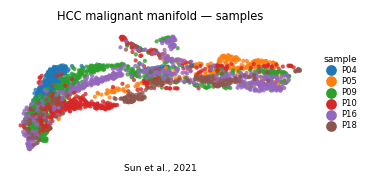

In [11]:
plot = adata.copy()
xy = plot.obsm['X_umap'].astype(float)
plot.obsm['X_umap'] = np.column_stack([xy[:,0], xy[:,1]])    # raw coords; pseudotime left->right (02: orient_sx=+1)
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('HCC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Sun et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])